# Life expectancy and missing birth and death dates

**Input** — `data/cultura/cultura_enriched_v3.2.duckdb`, the copy of the non-enriched V3 with the meta occupation added:
- the Wikidata birth and death dates of each individual (`individual.birth_date`, `individual.death_date`, entries with no rule in their provenance);
- the meta occupation of their occupations (`occupation.meta_occupation`); an individual takes the one most of their occupations have, else the first listed, and `Missing` when none has one.

**Rule** (`scripts/4-database_enrichment/13_individual_dates_from_life_expectancy.py`) — the life expectancy is death year minus birth year, for the individuals whose two dates are stated to the year or finer and 0 to 110 years apart. It is averaged per meta occupation and century: the century of birth to estimate a missing death, the century of death to estimate a missing birth. A cohort with fewer than 10 individuals takes the mean of the closest century of the same meta occupation that has 10 (the later one on a tie).
- missing death = birth year + mean life expectancy of the cohort, only for someone born more than 110 years before 2026;
- missing birth = death year − mean life expectancy of the cohort.

**Output** — the estimated year appended to `individual.birth_date` or `individual.death_date` of the same database, its provenance rule starting with *Estimated from life expectancy:* and naming the cohort used.

In [1]:
import tempfile
import numpy as np
import polars as pl
import duckdb
import matplotlib.pyplot as plt
from style import *

DB_PATH = '../data/cultura/cultura_enriched_v3.2.duckdb'
CENTURY = 100
MIN_LIVES = 10
LIFE_MIN, LIFE_MAX = 0, 110
CURRENT_YEAR, OLDEST_AGE = 2026, 110
STATED = ['day', 'month', 'year']
KNOWN = ['day', 'month', 'year', 'decade']
FIRST_CENTURY = -800
LAST_BIRTH_CENTURY = 1900
ESTIMATED = 'Estimated from life expectancy:%'
META_OCCUPATIONS = [*OCCUPATION_COLORS, 'Other', 'Missing']

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(12)
apply_style()

## Load the data

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH held AS (
        SELECT entity.qid AS qid, unnest(occupation).entity.qid AS occupation_qid, generate_subscripts(occupation, 1) AS position
        FROM individual
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN occupation ON occupation.entity.qid = held.occupation_qid
        WHERE occupation.meta_occupation IS NOT NULL
        GROUP BY ALL
    ),
    main_meta_occupation AS (
        SELECT qid, meta_occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    ),
    dates AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL) AS wikidata_birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL) AS wikidata_death,
               list_filter(birth_date, d -> d.field_provenance['year'].rule LIKE $estimated)[1] AS estimated_birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule LIKE $estimated)[1] AS estimated_death
        FROM individual
    )
    SELECT dates.qid,
           coalesce(main_meta_occupation.meta_occupation, 'Missing') AS meta_occupation,
           len(dates.wikidata_birth) = 0 AS no_birth,
           len(dates.wikidata_death) = 0 AS no_death,
           list_filter(dates.wikidata_birth, d -> list_contains($known, d.precision))[1].year AS birth_year,
           list_filter(dates.wikidata_death, d -> list_contains($known, d.precision))[1].year AS death_year,
           list_contains($stated, dates.wikidata_birth[1].precision) AND list_contains($stated, dates.wikidata_death[1].precision) AS both_stated,
           dates.estimated_birth.year AS estimated_birth_year,
           dates.estimated_death.year AS estimated_death_year,
           dates.estimated_birth.field_provenance['year'].rule AS estimated_birth_rule,
           dates.estimated_death.field_provenance['year'].rule AS estimated_death_rule
    FROM dates
    LEFT JOIN main_meta_occupation ON main_meta_occupation.qid = dates.qid
''', params={'estimated': ESTIMATED, 'known': KNOWN, 'stated': STATED}).pl()
con.close()
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals')

13,002,897 individuals


## 1. Missing birth and death dates

A date is missing when Wikidata gives none, at any precision. A missing death includes the living.

In [3]:
pl.DataFrame({
    'individuals': [people.height],
    '% missing birth': [round(100 * people['no_birth'].mean(), 1)],
    '% missing death': [round(100 * people['no_death'].mean(), 1)],
    '% missing both': [round(100 * (people['no_birth'] & people['no_death']).mean(), 1)],
    '% with both': [round(100 * (~people['no_birth'] & ~people['no_death']).mean(), 1)],
})

individuals,% missing birth,% missing death,% missing both,% with both
i64,f64,f64,f64,f64
13002897,42.4,72.8,40.4,25.1


### Distribution of the missing dates, by the century of the date that remains

Individuals missing a death, by the century of their birth; individuals missing a birth, by the century of their death. The remaining date is the first Wikidata one stated to the decade or finer.

In [4]:
def century_label(start):
    return f'{start}–{start + CENTURY - 1}' if start >= 0 else f'{-start}–{-(start + CENTURY - 1)} BC'


def per_century(frame, anchor, name):
    return frame.filter(pl.col(anchor) >= FIRST_CENTURY).group_by((pl.col(anchor) // CENTURY * CENTURY).alias('century')).agg(pl.len().alias(name))


missing_death = people.filter(pl.col('no_death') & pl.col('birth_year').is_not_null())
missing_birth = people.filter(pl.col('no_birth') & pl.col('death_year').is_not_null())
missing = (
    per_century(missing_death, 'birth_year', 'missing death')
    .join(per_century(missing_birth, 'death_year', 'missing birth'), on='century', how='full', coalesce=True)
    .fill_null(0)
    .sort('century')
)
print(f'{missing_death.height:,} missing a death have a birth, {missing_birth.height:,} missing a birth have a death')
missing.with_columns(pl.col('century').map_elements(century_label, return_dtype=pl.String).alias('label'))

4,130,793 missing a death have a birth, 258,435 missing a birth have a death


century,missing death,missing birth,label
i64,u32,u32,str
-800,6,42,"""800–701 BC"""
-700,6,71,"""700–601 BC"""
-600,34,87,"""600–501 BC"""
-500,20,92,"""500–401 BC"""
-400,40,113,"""400–301 BC"""
-300,69,146,"""300–201 BC"""
-200,81,121,"""200–101 BC"""
-100,122,178,"""100–1 BC"""
0,95,281,"""0–99"""


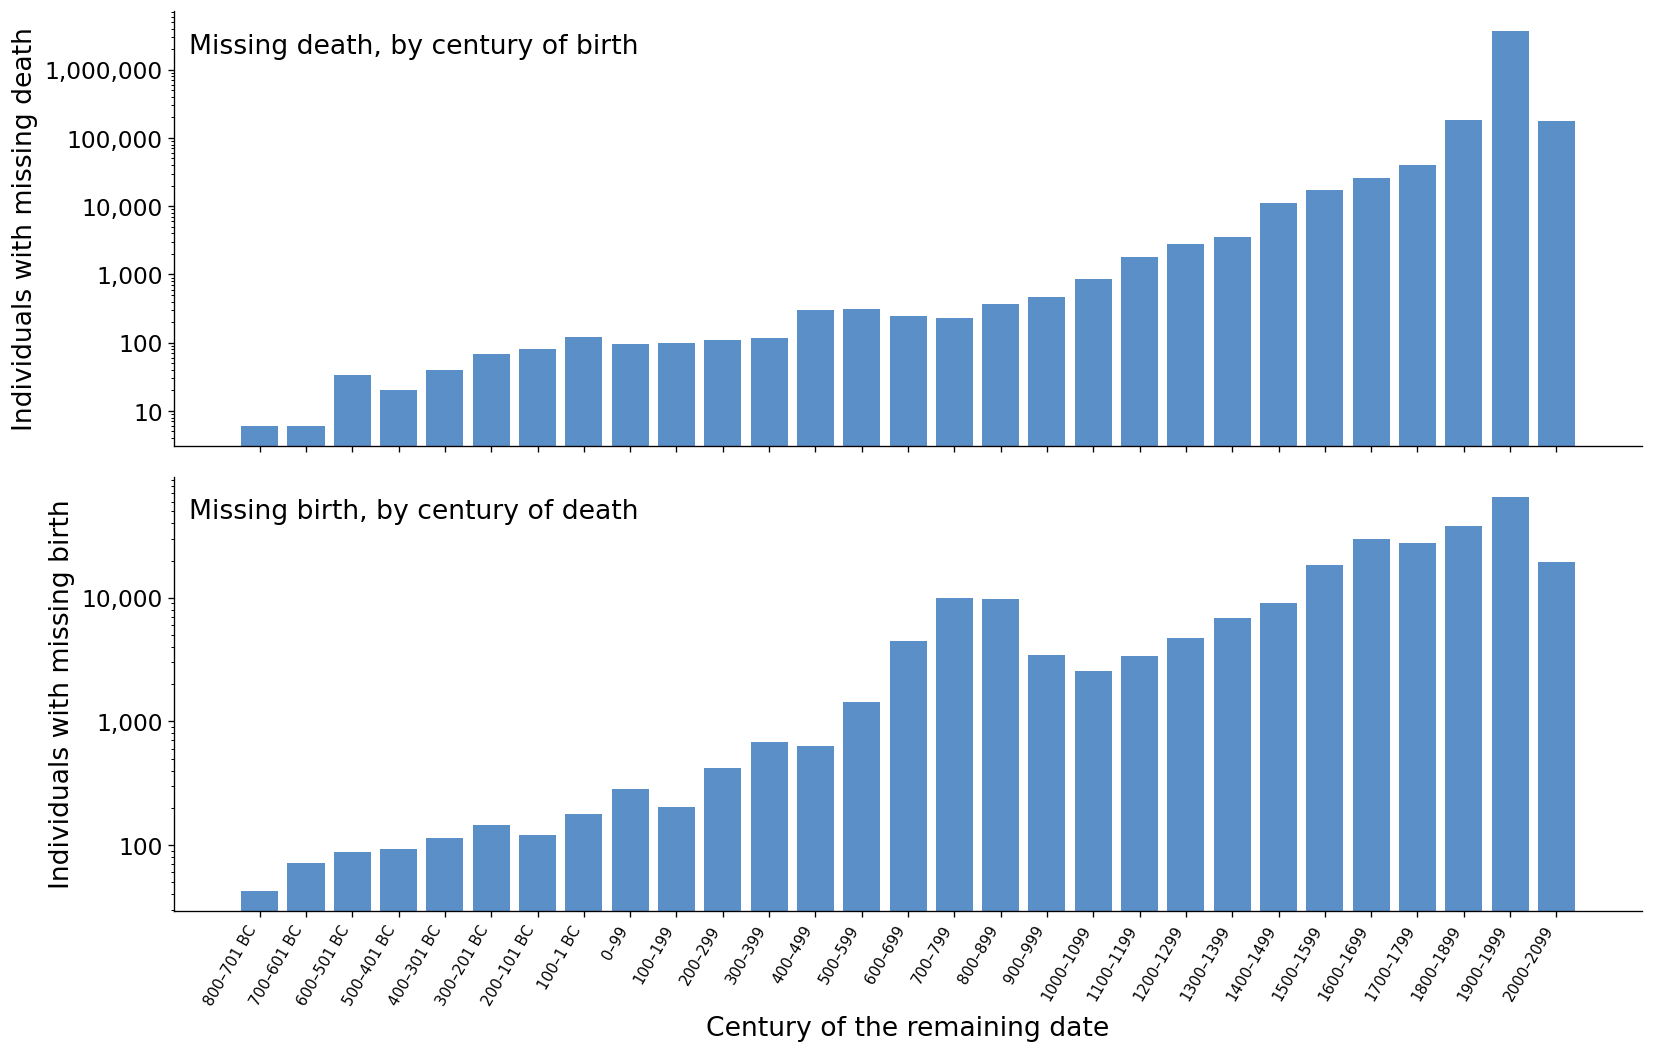

In [5]:
def set_century_axis(ax, starts):
    ax.set_xticks(starts)
    ax.set_xticklabels([century_label(start) for start in starts], rotation=60, ha='right', fontsize=9)


fig, axes = plt.subplots(2, 1, figsize=FIGSIZE_GRID, sharex=True)
for ax, column, anchor in zip(axes, ['missing death', 'missing birth'], ['birth', 'death']):
    ax.bar(missing['century'], missing[column], width=CENTURY * 0.8, color=MAIN_COLOR)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.set_ylabel(f'Individuals with {column}')
    ax.text(0.01, 0.95, f'{column.capitalize()}, by century of {anchor}', transform=ax.transAxes, fontsize=PANEL_LABEL_FONTSIZE, va='top')
    ax.grid(axis='x', visible=False)
set_century_axis(axes[-1], missing['century'].to_list())
axes[-1].set_xlabel('Century of the remaining date')
plt.tight_layout()
plt.show()

## 2. Life expectancy of the individuals with both dates

The individuals the estimate is measured on: Wikidata birth and death both stated to the year or finer, 0 to 110 years apart. The box spans the first to the third quartile, whiskers to 1.5 times the interquartile range; the line and the number are the **mean**. Centuries with fewer than 10 individuals are not shown, nor births after 1999 (only those who died young).

In [6]:
lives = (
    people.filter(pl.col('both_stated'))
    .with_columns((pl.col('death_year') - pl.col('birth_year')).alias('life_expectancy'))
    .filter(pl.col('life_expectancy').is_between(LIFE_MIN, LIFE_MAX))
    .with_columns(
        (pl.col('birth_year') // CENTURY * CENTURY).alias('birth_century'),
        (pl.col('death_year') // CENTURY * CENTURY).alias('death_century'),
    )
)
print(f'{lives.height:,} individuals with both dates')
lives.group_by('meta_occupation').agg(pl.len().alias('individuals'), pl.col('life_expectancy').mean().round(1).alias('mean life expectancy')).sort('individuals', descending=True)

3,115,252 individuals with both dates


meta_occupation,individuals,mean life expectancy
str,u32,f64
"""Missing""",809743,63.9
"""Culture""",750071,70.3
"""Leadership""",743506,68.6
"""Discovery/Science""",515930,73.0
"""Sports/Games""",199352,69.4
"""Other""",96650,68.0


In [7]:
def century_stats(frame, anchor):
    return (
        frame.filter(pl.col(anchor).is_between(FIRST_CENTURY, LAST_BIRTH_CENTURY if anchor == 'birth_century' else CURRENT_YEAR))
        .group_by(pl.col(anchor).alias('century'))
        .agg(pl.len().alias('individuals'), pl.col('life_expectancy').mean().round(1).alias('mean'))
        .filter(pl.col('individuals') >= MIN_LIVES)
        .sort('century')
    )


def plot_boxes(ax, frame, anchor, color):
    rows = century_stats(frame, anchor)
    starts = rows['century'].to_list()
    values = [frame.filter(pl.col(anchor) == start)['life_expectancy'].to_numpy() for start in starts]
    ax.boxplot(values, positions=starts, widths=CENTURY * 0.6, showfliers=False, patch_artist=True, showmeans=True, meanline=True,
               boxprops=dict(facecolor=color, alpha=BAND_ALPHA, edgecolor=color), medianprops=dict(linewidth=0),
               meanprops=dict(color=color, linewidth=2, linestyle='-'), whiskerprops=dict(color=color), capprops=dict(color=color))
    for start, mean in zip(starts, rows['mean']):
        ax.annotate(f'{mean:.0f}', (start + CENTURY * 0.32, mean), ha='left', va='center', fontsize=9, color=color)
    set_century_axis(ax, starts)
    ax.set_xlim(FIRST_CENTURY - CENTURY, max(starts) + CENTURY)
    ax.set_ylim(LIFE_MIN, LIFE_MAX)
    ax.set_ylabel('Life expectancy (years)')
    ax.grid(axis='x', visible=False)
    return rows


def plot_by_occupation(anchor, label):
    fig, axes = plt.subplots(3, 2, figsize=(14, 13), sharey=True)
    colors = {**OCCUPATION_COLORS, 'Other': SLATE, 'Missing': GREY}
    for ax, occupation in zip(axes.flat, META_OCCUPATIONS):
        ax.text(0.02, 0.95, occupation, transform=ax.transAxes, fontsize=PANEL_LABEL_FONTSIZE, color=colors[occupation], va='top', fontweight='bold')
        plot_boxes(ax, lives.filter(pl.col('meta_occupation') == occupation), anchor, colors[occupation])
    for ax in axes[-1, :]:
        ax.set_xlabel(label)
    plt.tight_layout()
    plt.show()

### Individuals per century of birth, by meta occupation

In [8]:
counts = (
    lives.filter(pl.col('birth_century') >= FIRST_CENTURY)
    .group_by('birth_century', 'meta_occupation').len()
    .pivot(on='meta_occupation', index='birth_century', values='len')
    .fill_null(0).sort('birth_century')
    .select('birth_century', *META_OCCUPATIONS)
    .with_columns(pl.sum_horizontal(META_OCCUPATIONS).alias('individuals'))
)
counts

birth_century,Culture,Discovery/Science,Leadership,Sports/Games,Other,Missing,individuals
i64,u32,u32,u32,u32,u32,u32,u32
-800,2,1,11,0,0,6,20
-700,6,4,15,0,1,3,29
-600,19,17,36,0,0,6,78
-500,29,31,52,2,1,7,122
-400,34,56,81,1,6,21,199
-300,15,26,132,0,4,20,197
-200,22,33,143,0,3,22,223
-100,31,29,196,0,5,54,315
0,21,30,164,1,10,42,268


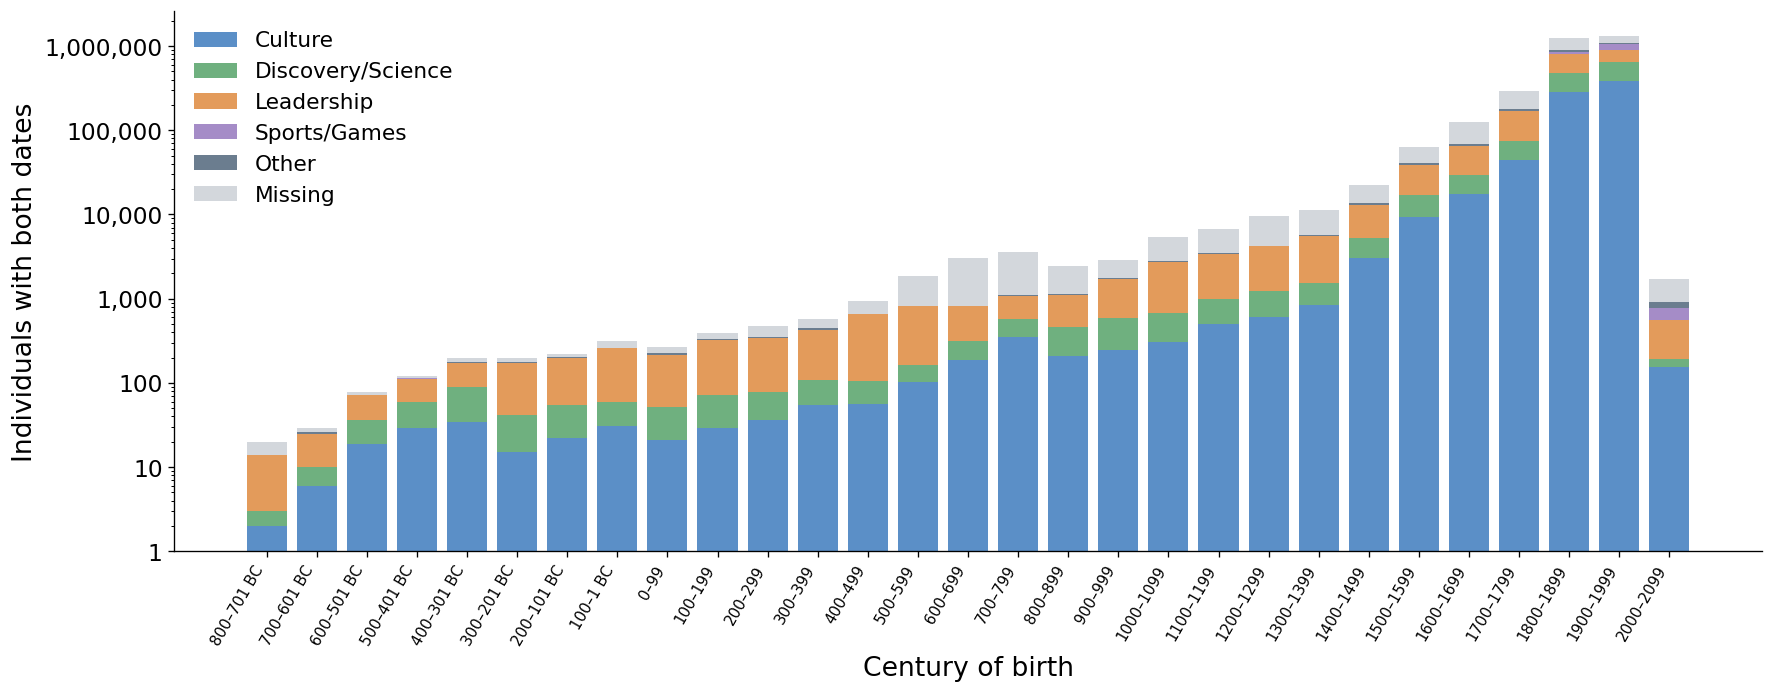

In [9]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
colors = {**OCCUPATION_COLORS, 'Other': SLATE, 'Missing': LIGHT_GREY}
bottom = np.zeros(counts.height)
for occupation in META_OCCUPATIONS:
    ax.bar(counts['birth_century'], counts[occupation], bottom=bottom, width=CENTURY * 0.8, color=colors[occupation], label=occupation)
    bottom += counts[occupation].to_numpy()
ax.set_yscale('log')
ax.set_ylim(bottom=1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.set_ylabel('Individuals with both dates')
ax.set_xlabel('Century of birth')
set_century_axis(ax, counts['birth_century'].to_list())
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

### Mean life expectancy per century of birth — used to estimate a missing death

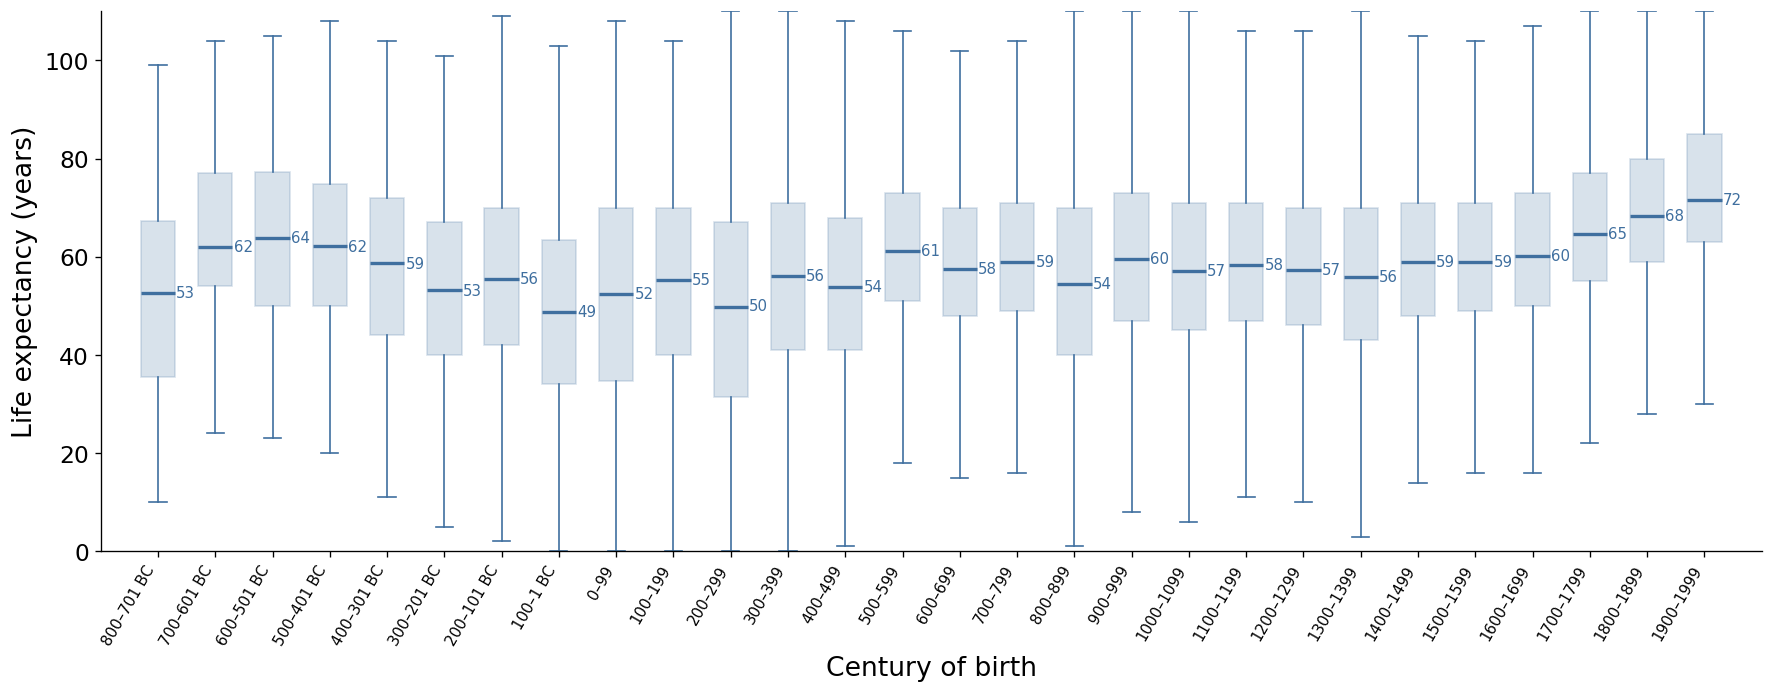

In [10]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
plot_boxes(ax, lives, 'birth_century', MAIN_LINE_COLOR)
ax.set_xlabel('Century of birth')
plt.tight_layout()
plt.show()

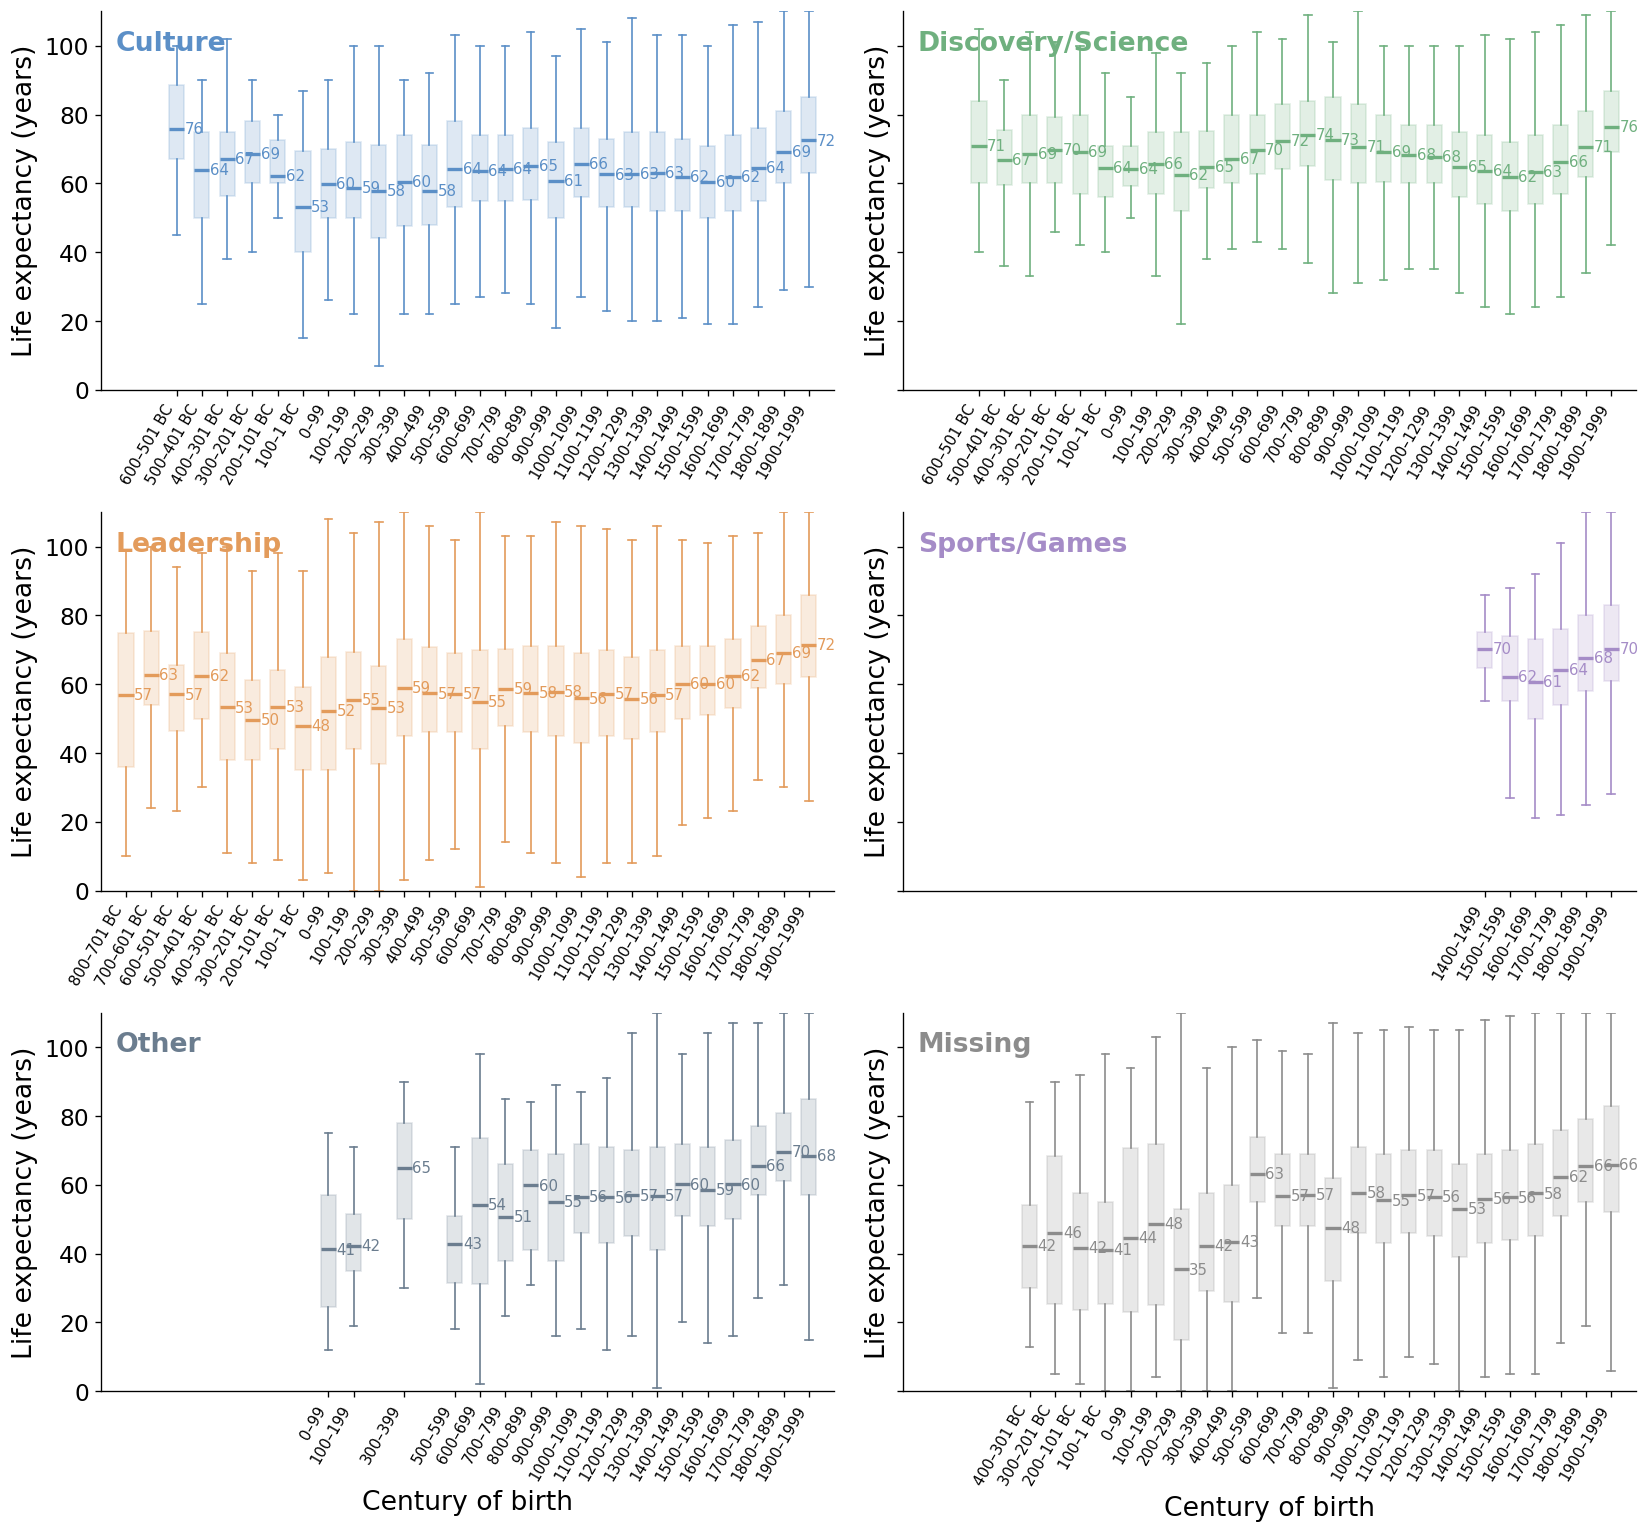

In [11]:
plot_by_occupation('birth_century', 'Century of birth')

### Mean life expectancy per century of death — used to estimate a missing birth

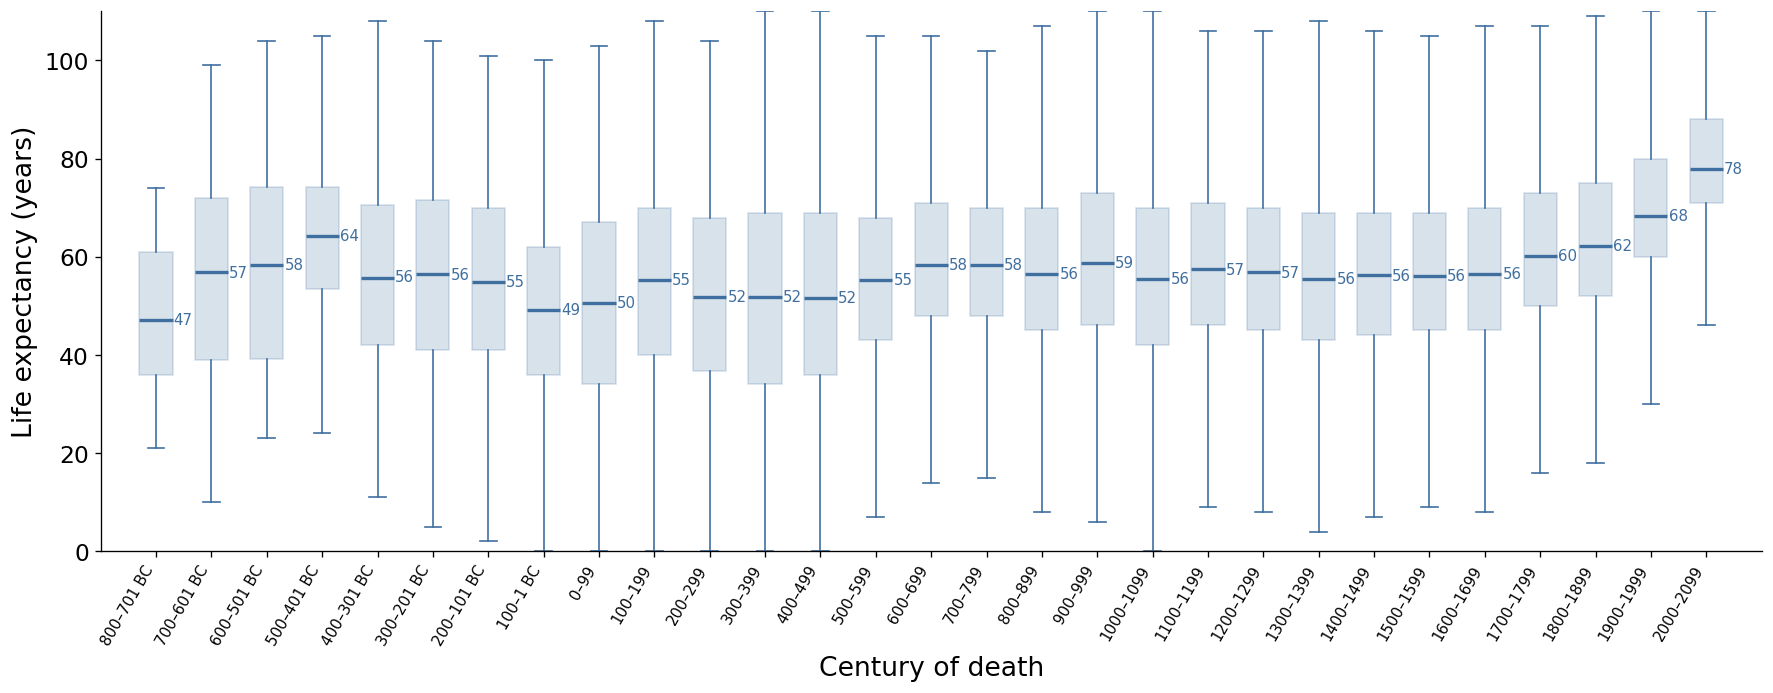

In [12]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
plot_boxes(ax, lives, 'death_century', MAIN_LINE_COLOR)
ax.set_xlabel('Century of death')
plt.tight_layout()
plt.show()

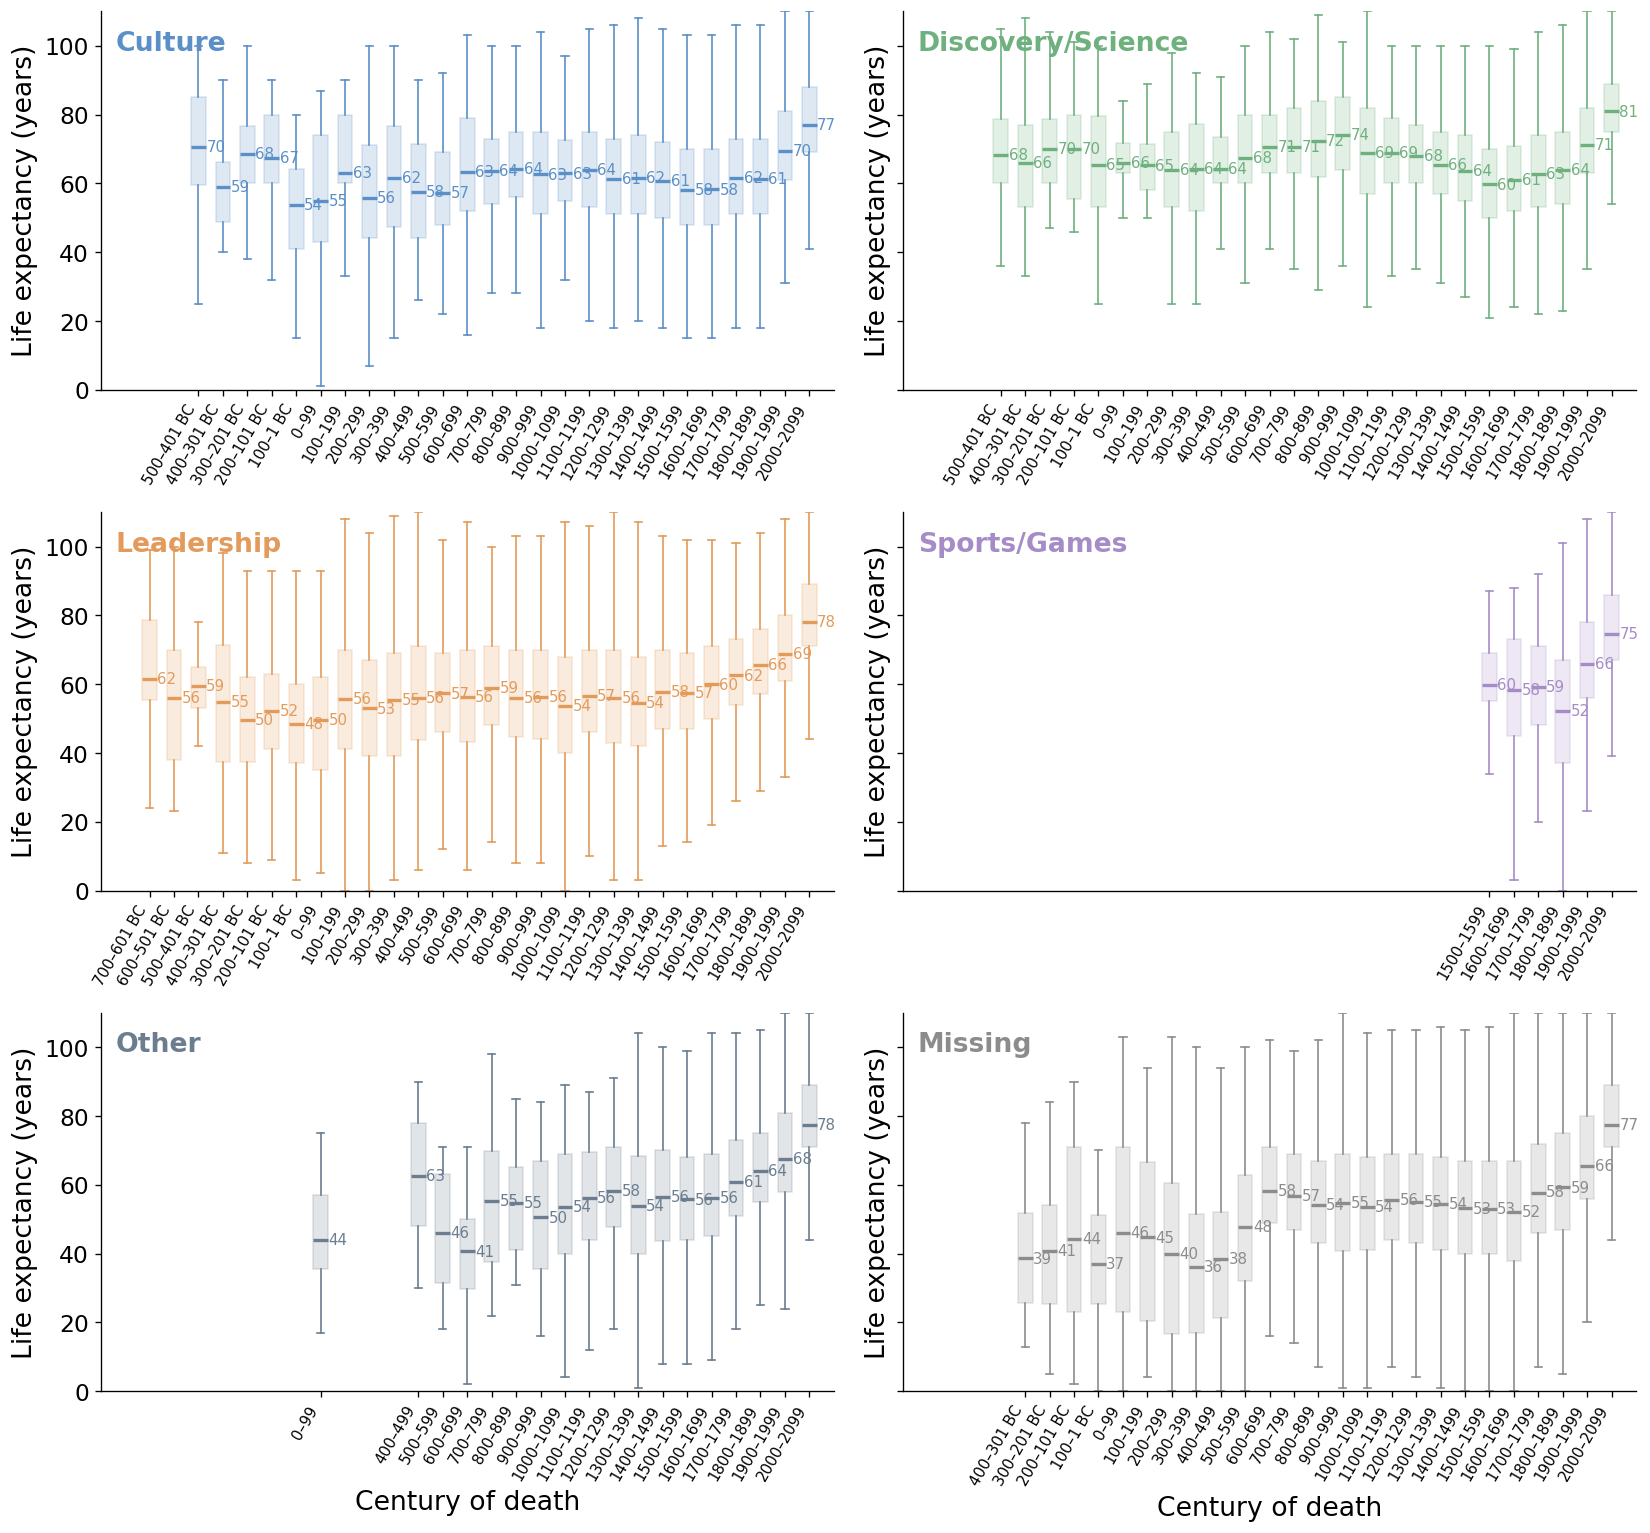

In [13]:
plot_by_occupation('death_century', 'Century of death')

## 3. Cohorts: mean life expectancy per meta occupation and century

The table the script uses, recomputed here. `used century` is the century the mean is taken from: the cohort's own when it has at least 10 individuals, else the closest one of the same meta occupation that has 10 (the later one on a tie).

In [14]:
def cohorts(anchor, wanted):
    cells = lives.group_by('meta_occupation', pl.col(anchor).alias('century')).agg(pl.len().alias('individuals'), pl.col('life_expectancy').mean().alias('mean'))
    large = cells.filter(pl.col('individuals') >= MIN_LIVES).select('meta_occupation', pl.col('century').alias('used century'), pl.col('mean').alias('used mean'))
    return (
        wanted.join(large, on='meta_occupation')
        .with_columns((pl.col('used century') - pl.col('century')).abs().alias('distance'))
        .sort('distance', 'used century', descending=[False, True])
        .group_by('meta_occupation', 'century', maintain_order=True).first()
        .join(cells.select('meta_occupation', 'century', 'individuals'), on=['meta_occupation', 'century'], how='left')
        .with_columns(pl.col('individuals').fill_null(0))
        .select('meta_occupation', 'century', 'individuals', 'used century', 'used mean')
        .sort('meta_occupation', 'century')
    )


death_targets = missing_death.filter(pl.col('birth_year') + OLDEST_AGE < CURRENT_YEAR).with_columns((pl.col('birth_year') // CENTURY * CENTURY).alias('century'))
birth_targets = missing_birth.with_columns((pl.col('death_year') // CENTURY * CENTURY).alias('century'))
death_cohorts = cohorts('birth_century', death_targets.select('meta_occupation', 'century').unique())
birth_cohorts = cohorts('death_century', birth_targets.select('meta_occupation', 'century').unique())

#### By century of birth (missing death)

In [15]:
death_cohorts.filter(pl.col('century') >= FIRST_CENTURY).with_columns(pl.col('used mean').round(1))

meta_occupation,century,individuals,used century,used mean
str,i64,u32,i64,f64
"""Culture""",-800,2,-600,75.8
"""Culture""",-700,6,-600,75.8
"""Culture""",-600,19,-600,75.8
"""Culture""",-500,29,-500,63.8
"""Culture""",-400,34,-400,67.0
"""Culture""",-300,15,-300,68.7
"""Culture""",-200,22,-200,62.2
"""Culture""",-100,31,-100,53.2
"""Culture""",0,21,0,59.9


#### By century of death (missing birth)

In [16]:
birth_cohorts.filter(pl.col('century') >= FIRST_CENTURY).with_columns(pl.col('used mean').round(1))

meta_occupation,century,individuals,used century,used mean
str,i64,u32,i64,f64
"""Culture""",-700,4,-500,70.5
"""Culture""",-400,20,-400,59.0
"""Culture""",-300,32,-300,68.5
"""Culture""",-200,17,-200,67.4
"""Culture""",-100,32,-100,53.7
"""Culture""",0,23,0,54.8
"""Culture""",100,21,100,63.1
"""Culture""",200,32,200,55.7
"""Culture""",300,46,300,61.5


## 4. Output: the estimated dates in the database

Each estimate read back from `cultura_enriched_v3.2` must equal the remaining year plus or minus the rounded mean of its cohort above.

In [17]:
check_death = death_targets.join(death_cohorts, on=['meta_occupation', 'century']).with_columns((pl.col('birth_year') + pl.col('used mean').round()).cast(pl.Int64).alias('expected'))
check_birth = birth_targets.join(birth_cohorts, on=['meta_occupation', 'century']).with_columns((pl.col('death_year') - pl.col('used mean').round()).cast(pl.Int64).alias('expected'))
assert (check_death['expected'] == check_death['estimated_death_year']).all()
assert (check_birth['expected'] == check_birth['estimated_birth_year']).all()
assert people['estimated_death_year'].is_not_null().sum() == check_death.height
assert people['estimated_birth_year'].is_not_null().sum() == check_birth.height

summary = []
for missing_date, frame, targets, check in [('death', missing_death, death_targets, check_death), ('birth', missing_birth, birth_targets, check_birth)]:
    borrowed = check.filter(pl.col('used century') != pl.col('century'))
    summary.append({
        'missing': missing_date,
        'missing, with the other date': frame.height,
        'can be estimated': targets.height,
        'estimated': check.height,
        '% of missing estimated': round(100 * check.height / frame.height, 1),
        'from a borrowed century': borrowed.height,
        'mean estimated life expectancy': round(check['used mean'].mean(), 1),
    })
pl.DataFrame(summary)

missing,"missing, with the other date",can be estimated,estimated,% of missing estimated,from a borrowed century,mean estimated life expectancy
str,i64,i64,i64,f64,i64,f64
"""death""",4130793,368458,368458,8.9,94,65.3
"""birth""",258435,258435,258435,100.0,244,61.0


A missing death can be estimated only for someone born before 1916, who cannot still be alive.

### Examples

In [18]:
pl.concat([
    check_death.sample(5, seed=42).select('qid', 'meta_occupation', 'birth_year', pl.col('estimated_death_year').alias('estimated year'), pl.col('estimated_death_rule').str.extract(r'Here (.*)$').alias('cohort')),
    check_birth.sample(5, seed=42).select('qid', 'meta_occupation', 'death_year', pl.col('estimated_birth_year').alias('estimated year'), pl.col('estimated_birth_rule').str.extract(r'Here (.*)$').alias('cohort')).rename({'death_year': 'birth_year'}),
]).rename({'birth_year': 'remaining year'})

qid,meta_occupation,remaining year,estimated year,cohort
str,str,i64,i64,str
"""Q132143950""","""Missing""",1884,1950,"""65.5 years, the mean of 341,43…"
"""Q75449872""","""Missing""",1610,1668,"""57.5 years, the mean of 57,142…"
"""Q95238919""","""Other""",1914,1982,"""68.5 years, the mean of 37,561…"
"""Q79637059""","""Missing""",1818,1884,"""65.5 years, the mean of 341,43…"
"""Q45449272""","""Missing""",1858,1924,"""65.5 years, the mean of 341,43…"
"""Q28857092""","""Culture""",1610,1552,"""58.2 years, the mean of 13,068…"
"""Q65802808""","""Missing""",665,607,"""58.3 years, the mean of 1,896 …"
"""Q95304972""","""Missing""",1631,1579,"""52.1 years, the mean of 36,978…"
"""Q137804119""","""Leadership""",1916,1847,"""68.8 years, the mean of 365,58…"
